In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import transforms
from tqdm import tqdm
import os
import pandas as pd
import matplotlib.pyplot as plt
import timm
from sklearn.model_selection import train_test_split
from PIL import Image

In [28]:
import timm
models = [m for m in timm.list_models() if 'swinv2' in m]
models

['swinv2_base_window8_256',
 'swinv2_base_window12_192',
 'swinv2_base_window12to16_192to256',
 'swinv2_base_window12to24_192to384',
 'swinv2_base_window16_256',
 'swinv2_cr_base_224',
 'swinv2_cr_base_384',
 'swinv2_cr_base_ns_224',
 'swinv2_cr_giant_224',
 'swinv2_cr_giant_384',
 'swinv2_cr_huge_224',
 'swinv2_cr_huge_384',
 'swinv2_cr_large_224',
 'swinv2_cr_large_384',
 'swinv2_cr_small_224',
 'swinv2_cr_small_384',
 'swinv2_cr_small_ns_224',
 'swinv2_cr_small_ns_256',
 'swinv2_cr_tiny_224',
 'swinv2_cr_tiny_384',
 'swinv2_cr_tiny_ns_224',
 'swinv2_large_window12_192',
 'swinv2_large_window12to16_192to256',
 'swinv2_large_window12to24_192to384',
 'swinv2_small_window8_256',
 'swinv2_small_window16_256',
 'swinv2_tiny_window8_256',
 'swinv2_tiny_window16_256']

# gender

In [18]:
#UTK
path = '/kaggle/input/utkface-new/UTKFace'
files = os.listdir(path)
gender_list = []
file_names = []
for file in files:
    gender = int(file.split('_')[1])
    gender_list.append(gender)
    file_names.append(f'/kaggle/input/utkface-new/UTKFace/{file}')
data = {"file_name": file_names, "gender": gender_list}
df = pd.DataFrame(data)
print(df)

                                               file_name  gender
0      /kaggle/input/utkface-new/UTKFace/26_0_2_20170...       0
1      /kaggle/input/utkface-new/UTKFace/22_1_1_20170...       1
2      /kaggle/input/utkface-new/UTKFace/21_1_3_20170...       1
3      /kaggle/input/utkface-new/UTKFace/28_0_0_20170...       0
4      /kaggle/input/utkface-new/UTKFace/17_1_4_20170...       1
...                                                  ...     ...
23703  /kaggle/input/utkface-new/UTKFace/41_0_0_20170...       0
23704  /kaggle/input/utkface-new/UTKFace/42_0_0_20170...       0
23705  /kaggle/input/utkface-new/UTKFace/2_0_2_201612...       0
23706  /kaggle/input/utkface-new/UTKFace/65_1_0_20170...       1
23707  /kaggle/input/utkface-new/UTKFace/66_0_1_20170...       0

[23708 rows x 2 columns]


In [19]:
transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [20]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [21]:
class GenderDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'file_name']
        label = int(self.df.loc[idx, 'gender'])

        image = Image.open(img_path).convert('RGB')

        if image:
            image = self.transform(image)
            
        return image, label

        
class EmotionDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'path']
        label = int(self.df.loc[idx, 'label'])

        image = Image.open(img_path).convert('RGB')

        if image:
            image = self.transform(image)

        return image, label

In [22]:
#dataset = EmotionDataset(df, transform)
# total_size = len(dataset)
# train_size = int(0.70 * total_size)
# val_size = int(0.15 * total_size)
# test_size = int(total_size - train_size - val_size)
#train_data, test_data, val_data = random_split(dataset, [train_size, val_size, test_size])

train_data, test_data = train_test_split(df, test_size=0.2, random_state=42)
train_data, val_data = train_test_split(train_data, test_size=0.2, random_state=42)

train_dataset = GenderDataset(train_data, transform)
test_dataset = GenderDataset(test_data, transform_test)
val_dataset = GenderDataset(val_data, transform)

In [23]:
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader= DataLoader(test_dataset, batch_size=128)
val_loader = DataLoader(val_dataset, batch_size=128)

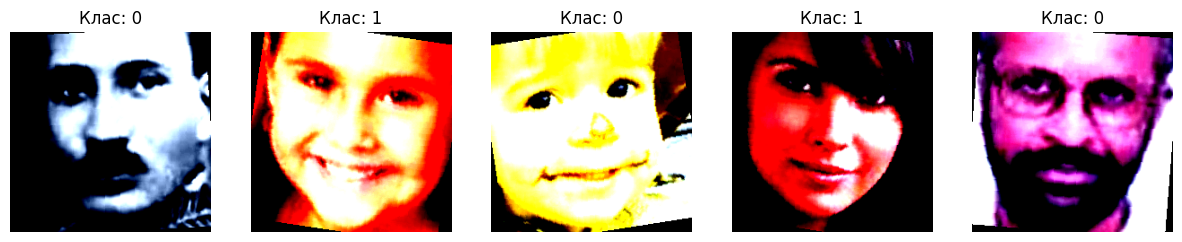

In [24]:
def show_images(data_loader):
    images, labels = next(iter(data_loader))
    fig, axes = plt.subplots(1, 5, figsize=(15, 4))
    for i in range(5):
        img = images[i].permute(1, 2, 0)
        axes[i].imshow(img)
        axes[i].set_title(f"Клас: {labels[i].item()}")
        axes[i].axis('off')
    plt.show()

show_images(val_loader)

In [36]:
len(train_loader)

238

# Classification

In [12]:
from timm.data import Mixup

cutmix_or_mixup = Mixup(
    mixup_alpha=0.2,        
    cutmix_alpha=0.2,       
    cutmix_minmax=None,      
    prob=0.5,                
    switch_prob=0.5,        
    mode='batch',          
    label_smoothing=0.05,    
    num_classes=2            
)

# With augm

In [23]:
def train(model, train_loader, val_loader, criterion, val_criterion, optimizer,epochs=30, device='cpu'):
    best_model_path = "/kaggle/working/best_model.pth"
    epoch_without_improvement = 0
    best_val_acc = 0.0
    train_loss = []
    train_acc = []
    val_loss = []
    val_accuracies = []
    

    for epoch in range(1, epochs+1):
        total = 0
        model.train()
        total_train_loss,total_train_acc = 0.0, 0.0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            images,labels = cutmix_or_mixup(images, labels)
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            
            loss.backward()
            optimizer.step()
            total_train_loss +=loss.item()
            _, predicted = outputs.max(1)
            _, targets = labels.max(1)
            total += labels.size(0)
            total_train_acc += predicted.eq(targets).sum().item()
            
        avg_train_loss = total_train_loss/len(train_loader)
        avg_train_acc = total_train_acc/total
        
        train_loss.append(avg_train_loss)
        train_acc.append(avg_train_acc)

        model.eval()
        total_val_loss =0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = val_criterion(outputs, labels)
                total_val_loss += loss.item() * images.size(0) 
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        avg_val_loss = total_val_loss / total
        scheduler.step(avg_val_loss)
        accuracy = correct / total
        val_accuracies.append(accuracy)
        val_loss.append(avg_val_loss)
        print(
                f"[epoch {epoch}/{epochs}] "
                f"Train accuracy {avg_train_acc:.4f} | "
                f"Train loss {avg_train_loss:.4f} | "
                f"Val loss {avg_val_loss:.4f} |"
                f"Val accuracy {accuracy:.4f}"
        )


        if accuracy > best_val_acc:
            best_val_acc = accuracy
            torch.save(model.state_dict(), best_model_path)
            print(f'Best model with updated with accuracy: {best_val_acc:.4f}')
            epoch_without_improvement = 0
        else:
            epoch_without_improvement+=1

        if epoch_without_improvement > 4:
            print(f"Early stopping after {epoch} epochs without improvement.")
            return train_loss, train_acc, val_loss, val_accuracies
            
    return train_loss, train_acc, val_loss, val_accuracies
        
            
            

In [23]:
#'swin_tiny_patch4_window7_224', 'convnextv2_tiny', 'coatnet_0_rw_224'

In [ ]:
from torchsummary import summary
count= 0
for param in model.parameters():
    count+=1
print(count)

summary(model, (3,224,224))

In [31]:
import torch
import torch.nn as nn
import timm
from timm.loss import SoftTargetCrossEntropy

# Complete fresh start
if 'model' in globals():
    del model
torch.cuda.empty_cache()

# Create wrapper model
class SwinClassifier(nn.Module):
    def __init__(self, num_classes=1):
        super(SwinClassifier, self).__init__()
        self.backbone = timm.create_model('convnextv2_tiny', 
                                          pretrained=True, 
                                          num_classes=0)
        
        num_features = self.backbone.num_features
        self.classifier = nn.Sequential(
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        features = self.backbone(x)  
        output = self.classifier(features) 
        return output



# Train head

In [ ]:

model = SwinClassifier(num_classes=1)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

for param in model.backbone.parameters():
    param.requires_grad = False
for param in model.classifier.parameters():
    param.requires_grad = True


#criterion = nn.CrossEntropyLoss()
criterion = SoftTargetCrossEntropy()
val_criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=0.00001, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-8, verbose=True
)

# Now train
train_loss, train_acc, val_loss, val_accuracies = train(
    model, train_loader, val_loader, criterion,val_criterion, optimizer, 
     epochs=50, device=device
)

# Training everything

In [20]:
for param in model.backbone.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

In [ ]:
for i,param in enumerate(model.backbone.parameters()):
    print(i,param.requires_grad )

In [70]:
from timm.loss import SoftTargetCrossEntropy
criterion = SoftTargetCrossEntropy()
val_criterion = nn.CrossEntropyLoss()

#criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {'params':model.backbone.parameters(), 'lr':0.000003}, 
    {'params':model.classifier.parameters(), 'lr':0.00001} 
],weight_decay=0.01
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-8, verbose=True
)

# Now train
train_loss, train_acc, val_loss, val_accuracies = train(
    model, train_loader, val_loader, criterion, val_criterion, optimizer, 
     epochs=25, device=device
)

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


[epoch 1/25] Train accuracy 0.8537 | Train loss 0.4056 | Val loss 0.2753 |Val accuracy 0.8848
Best model with updated with accuracy: 0.8848
[epoch 2/25] Train accuracy 0.8587 | Train loss 0.3972 | Val loss 0.2523 |Val accuracy 0.9012
Best model with updated with accuracy: 0.9012
[epoch 3/25] Train accuracy 0.8688 | Train loss 0.3815 | Val loss 0.2387 |Val accuracy 0.9083
Best model with updated with accuracy: 0.9083
[epoch 4/25] Train accuracy 0.8808 | Train loss 0.3639 | Val loss 0.2295 |Val accuracy 0.9122
Best model with updated with accuracy: 0.9122
[epoch 5/25] Train accuracy 0.8880 | Train loss 0.3556 | Val loss 0.2109 |Val accuracy 0.9167
Best model with updated with accuracy: 0.9167
[epoch 6/25] Train accuracy 0.8905 | Train loss 0.3472 | Val loss 0.2072 |Val accuracy 0.9193
Best model with updated with accuracy: 0.9193
[epoch 7/25] Train accuracy 0.8979 | Train loss 0.3447 | Val loss 0.1989 |Val accuracy 0.9225
Best model with updated with accuracy: 0.9225
[epoch 8/25] Train a

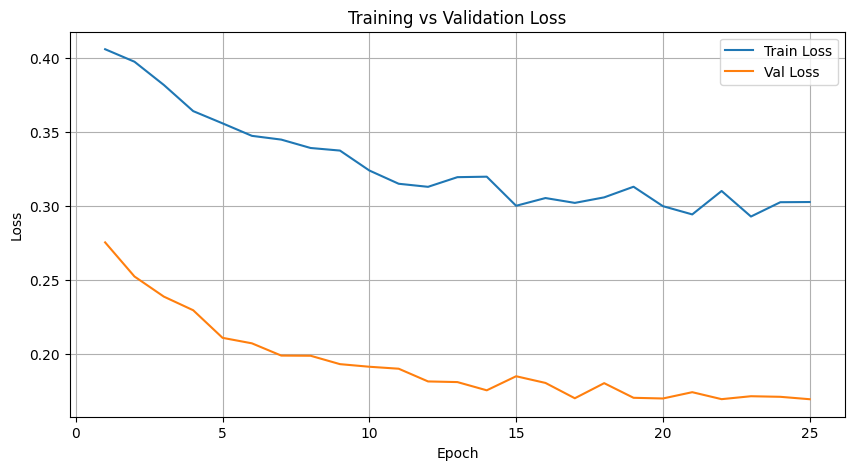

In [76]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

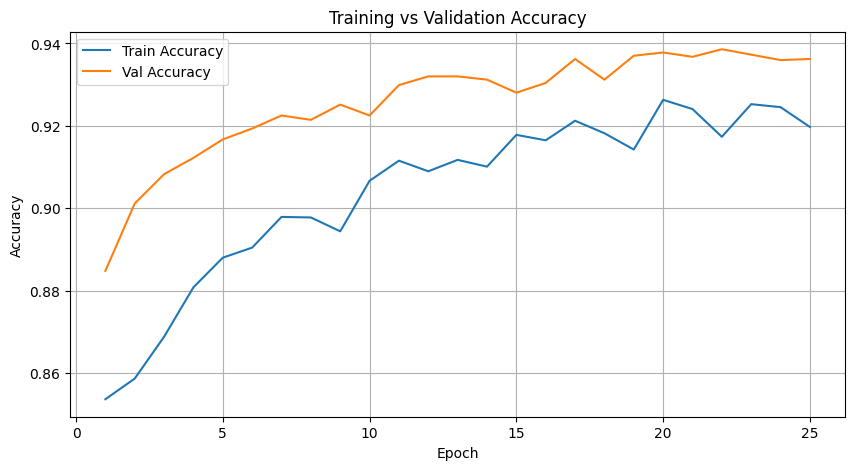

In [77]:
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_acc, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [27]:
torch.save(model.state_dict(), '/kaggle/working/best_model.pth')

In [32]:
model = SwinClassifier(num_classes=2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#path = '/kaggle/input/convnext-head-gender/convnext_head_gender.pth'
path = '/kaggle/input/full-gender-models/conv_full_gender_aug.pth'
model.load_state_dict(torch.load(path, map_location=device))
model = model.to(device)


model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

# Classification test 

In [33]:
val_criterion = nn.CrossEntropyLoss()
model.eval()
test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:  
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        
        loss = val_criterion(outputs, labels) 
        test_loss += loss.item() * images.size(0)
        
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

avg_test_loss = test_loss / total
accuracy = correct / total

print(f"Test loss: {avg_test_loss:.4f}")
print(f"Test accuracy: {accuracy:.4f}")

Test loss: 0.1480
Test accuracy: 0.9475


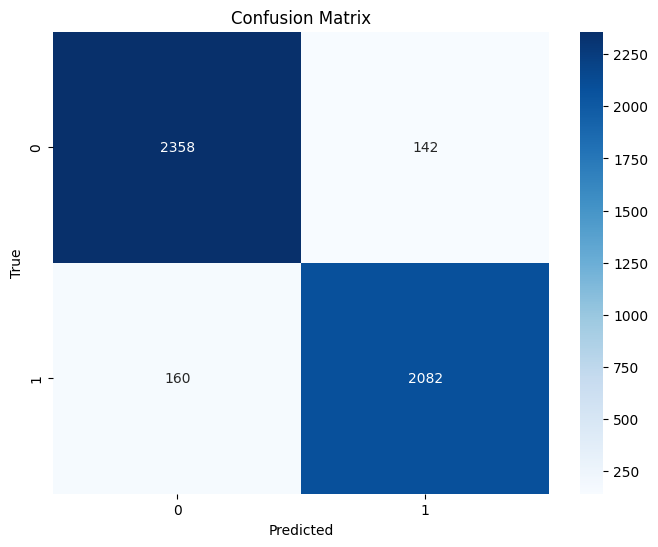

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

all_preds = []
all_labels = []
model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [81]:
from sklearn.metrics import confusion_matrix, classification_report
report = classification_report(all_labels, all_preds, target_names=['woman', 'man'])
print(report)

              precision    recall  f1-score   support

       woman       0.94      0.94      0.94      2500
         man       0.94      0.93      0.93      2242

    accuracy                           0.94      4742
   macro avg       0.94      0.94      0.94      4742
weighted avg       0.94      0.94      0.94      4742



# Results

### Full models, loss:
**ConvNeXt - 0.1492**

**Swin     - 0.1737**

**CoAtNet  - 0.1866**


### Full models, accuracy:
**ConvNeXt - 0.9475**

**Swin     - 0.9348**

**CoAtNet  - 0.93**
  

### Full models, F1 value:
**ConvNeXt - 0.9489**

**Swin     - 0.939**

**CoAtNet  - 0.933**